In [2]:
import matplotlib.pyplot as plt
import numpy as np
import math

In [3]:
prod = lambda arr: arr[-1] * prod(arr[:-1]) if arr else 1
comb = lambda n, k: prod(range(n-k+1, n+1)) // prod(range(1, k+1))
aranj = lambda n, k: prod(range(n-k+1, n+1))

In [4]:
bin_pdf = lambda n, p, x: comb(n, x) * p ** x * (1 - p) ** (n-x)
hy_pdf = lambda ab, a, k, x: comb(k, x) * aranj(a, x) * aranj(ab - a, k-x) / aranj(ab, k)

Text(0.5, 1.0, 'P(X >= x)')

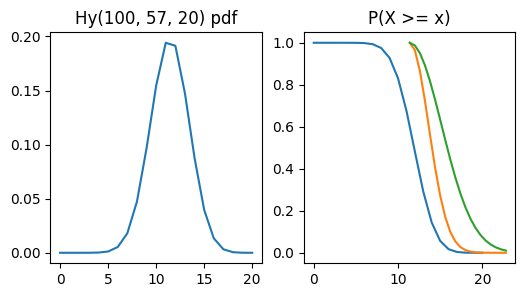

In [45]:
ab, a, k = 100, 57, 20
fig, ax = plt.subplots(1, 2, figsize = (6, 3))

ax[0].plot(range(k+1), [hy_pdf(ab, a, k, x) for x in range(k+1)])
ax[0].set_title(f"Hy({ab}, {a}, {k}) pdf")

ax[1].plot(range(k+1), np.cumsum([hy_pdf(ab, a, k, x) for x in range(k+1)][::-1])[::-1])

deltas = np.linspace(0, 1, 20)
ax[1].plot(k * a/ab * (1 + deltas), np.exp(-2*k * (a/ab)**2 * deltas**2))
ax[1].plot(k * a/ab * (1 + deltas), np.exp(-2*a * (k/ab)**2 * deltas**2))

ax[1].set_title(f"P(X >= x)")

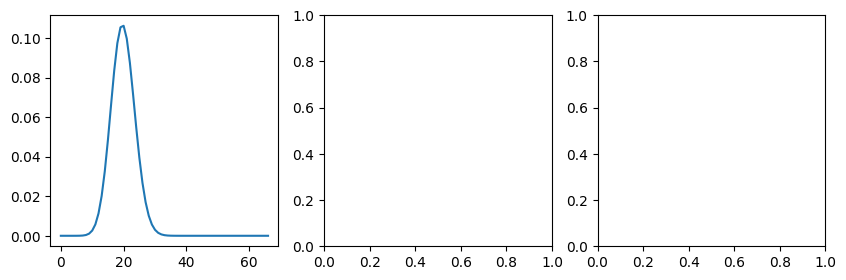

In [58]:
fig, ax = plt.subplots(1, 3, figsize = (10, 3))

n, p = int(20 / 0.3), 0.3
ax[0].plot(range(n+1), [bin_pdf(n, p, x) for x in range(n+1)])

# n, p = int(3 / 0.2), 0.2
# ax[0].plot(range(n+1), [bin_pdf(n, p, x) for x in range(n+1)])

# n, p = int(3 / 0.5), 0.5
# ax[0].plot(range(n+1), [bin_pdf(n, p, x) for x in range(n+1)])

In [34]:
def get_ev(h, p, nt, W):
    mean = 0
    for t in range(nt):
        Z = np.random.binomial(int((h-1) / p), p, size = (h**2-1,))

        mean += sum([1 - 1/Z[i] if Z[i] > 0 else 0 for i in range(h-1)]) +\
                sum([1 - 1/(h**2-1 - Z[i]) if h**2-1 - Z[i] > 0 else 0 for i in range(h, h**2-1)])

    mean /= nt

    return -mean

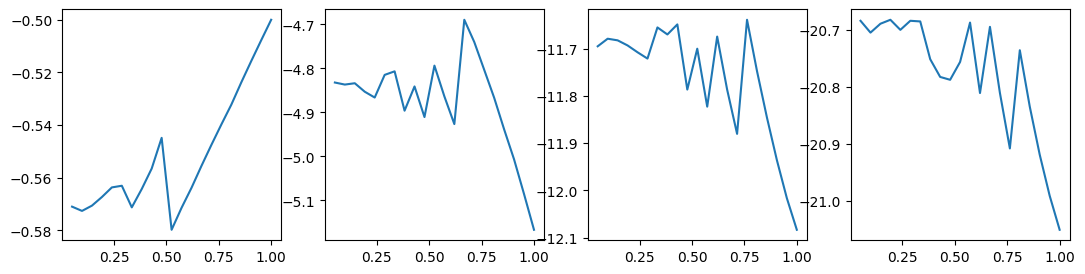

In [40]:
fig, ax = plt.subplots(1, 4, figsize = (13, 3))

ps = np.linspace(0.05, 1, 21)
nt, W = 3 * 10**4, 100

for i, h in enumerate([2, 3, 4, 5]):
    ax[i].plot(ps, [get_ev(h, p, nt, W) for p in ps])

In [83]:
def approx_proba(h, p, q, nt, W):
    better = 0
    for t in range(nt):
        Z_star = np.random.binomial(int(h*(h-1) / p), p, size = (h*(h-1),))
        Z = np.random.binomial(int((h-1) / p), p, size = (h-1,))

        Zbar_star = np.random.binomial(int(h*(h-1) / q), q, size = (h*(h-1),))
        Zbar = np.random.binomial(int((h-1) / q), q, size = (h-1,))

        lhs = sum([np.random.binomial(W * zs, 1/zs) if zs else 0 for zs in Z_star]) +\
              sum([np.random.binomial(W * z, 1/z) if z else 0 for z in Z])
        rhs = sum([np.random.binomial(W * zs, 1/zs) if zs else 0 for zs in Zbar_star]) +\
              sum([np.random.binomial(W * z, 1/z) if z else 0 for z in Zbar])

        better += lhs > rhs

    return better / nt

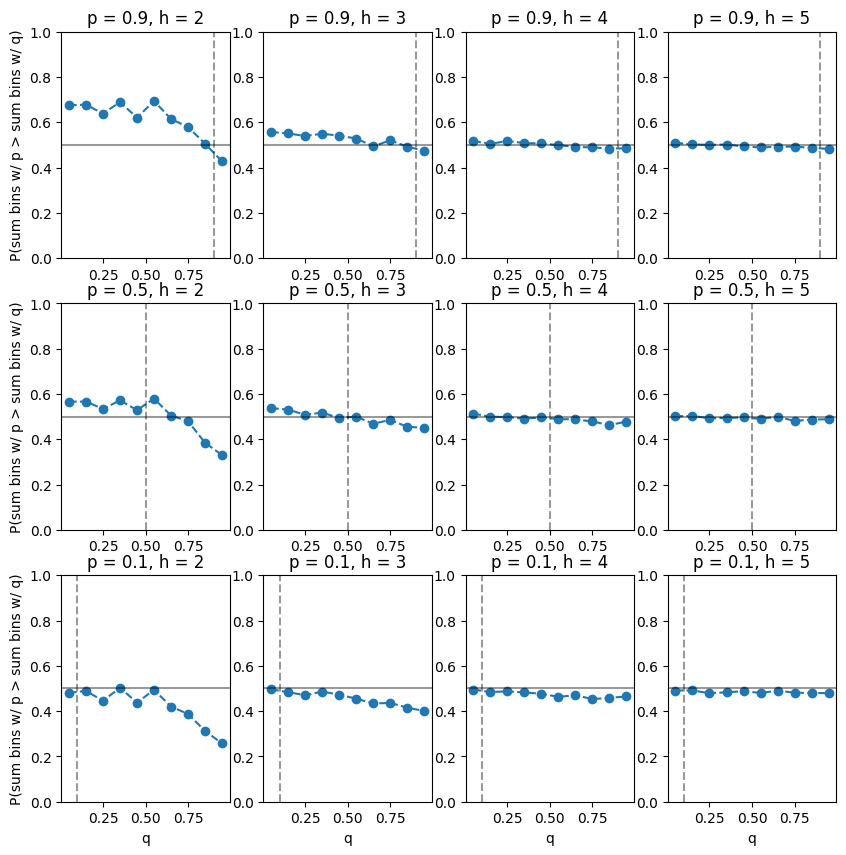

In [94]:
nt, W = 10 ** 4, 10

fig, ax = plt.subplots(3, 4, figsize = (10, 10))

qs = np.linspace(0.05, 0.95, 10)
for i, p in enumerate([0.9, 0.5, 0.1]):
    for j, h in enumerate([2, 3, 4, 5]):
        ax[i, j].set_ylim([0, 1])
        ax[i, j].plot(qs, [approx_proba(h, p, q, nt, W) for q in qs], ls = "--", marker = 'o')
        
        ax[i, j].axvline(p, c = 'k', alpha = 0.4, ls = "--")
        ax[i, j].axhline(0.5, c = 'k', alpha = 0.4)
        
        ax[i, j].set_title(f"{p = }, {h = }")
        
        if i == len(ax) - 1:
            ax[i, j].set_xlabel("q")
        
        if j == 0:
            ax[i, j].set_ylabel("P(sum bins w/ p > sum bins w/ q)")